In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [15]:
df= pd.read_csv("C:/Users/SEBASTIAN/Documents/Cursos/curso_ciencia_de_datos/30_days_of_python/Decision_Trees_y_Random_Forest/titanic.csv", sep= ",")
df.head()

,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500


In [16]:
df.drop(["Name","Fare"], axis= 1, inplace= True)

In [17]:
df.columns= ["Survived", "Pclass", "Sex", "Age", "SibSp", "ParCh"] #Renombrar las columnas
df.shape

(887, 6)

In [10]:
df.dtypes

Survived      int64
Pclass        int64
Sex          object
Age         float64
SibSp         int64
ParCh         int64
dtype: object

In [18]:
df= pd.get_dummies(df, columns= ["Sex"], drop_first= True)
df.head()

,Survived,Pclass,Age,SibSp,ParCh,Sex_male
0,0,3,22.0,1,0,True
1,1,1,38.0,1,0,False
2,1,3,26.0,0,0,False
3,1,1,35.0,1,0,False
4,0,3,35.0,0,0,True


In [20]:
df.rename(columns= {"Sex_male": "Sex"}, inplace= True) #Renombrar una columna especifica
df= df[["Survived", "Pclass", "Sex", "Age", "SibSp", "ParCh"]] # Ordenar columnas por nombres
df.head()

#Otra forma de hacer one hot encoding mas rapido
#df.Sex= df.Sex.apply(lambda x: 1 if x=="male" else 0) 

,Survived,Pclass,Sex,Age,SibSp,ParCh
0,0,3,True,22.0,1,0
1,1,1,False,38.0,1,0
2,1,3,False,26.0,0,0
3,1,1,False,35.0,1,0
4,0,3,True,35.0,0,0


In [26]:
X= df.drop("Survived", axis=1)
y= df.Survived

X_train, X_test, y_train, y_test= train_test_split(X,y, test_size= 0.3, random_state= 42)

#Creacion del modelo
tree= DecisionTreeClassifier(max_depth= 2, random_state= 42) #Dado que hay pocos datos, se usara una profundidad de 2, puesto que este modelo suele sobreajustarse

#Entrenar el modelo
tree.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=2, random_state=42)

In [27]:
#Predicciones
y_train_pred= tree.predict(X_train)
y_test_pred= tree.predict(X_test)

In [30]:
train_accuracy= accuracy_score(y_train, y_train_pred)
print("Train accuracy: ", train_accuracy)

test_accuracy= accuracy_score(y_test, y_test_pred)
print("Test accuracy: ", test_accuracy)

Train accuracy:  0.8064516129032258
Test accuracy:  0.7378277153558053


C:\Users\SEBASTIAN\AppData\Local\Temp\ipykernel_23796\401967424.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=columns, y=importances, palette= "bright", saturation= 2)


Text(0.5, 1.0, 'Feature´s importances')

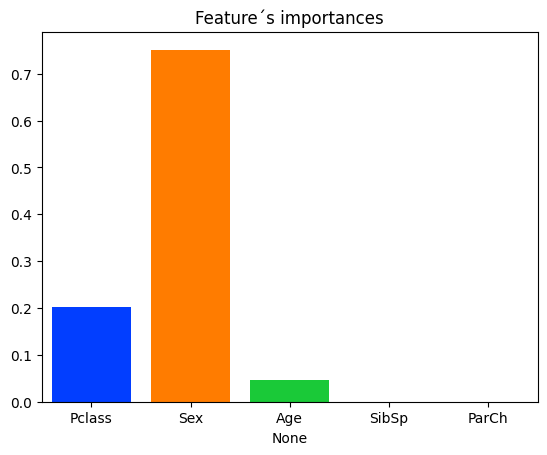

In [37]:
#Graficar importancia de las caracteristicas

importances= tree.feature_importances_
columns= X.columns

sns.barplot(x=columns, y=importances, palette= "bright", saturation= 2)
plt.title("Feature´s importances")